Authors: Myles Lewis & Joonseo Bang

Background information:
This dataset represents diabetes patient records and these were obtained from two sources. An automatic electronic recording device and paper records. In this notebook we will

Dataset: https://archive.ics.uci.edu/dataset/34/diabetes



In [5]:
!tar -xzvf "diabetes-data.tar[1].Z"

Diabetes-Data/
Diabetes-Data/data-01
Diabetes-Data/data-02
Diabetes-Data/data-03
Diabetes-Data/data-04
Diabetes-Data/data-05
Diabetes-Data/data-06
Diabetes-Data/data-07
Diabetes-Data/data-08
Diabetes-Data/data-09
Diabetes-Data/data-10
Diabetes-Data/data-11
Diabetes-Data/data-12
Diabetes-Data/data-13
Diabetes-Data/data-14
Diabetes-Data/data-15
Diabetes-Data/data-16
Diabetes-Data/data-17
Diabetes-Data/data-18
Diabetes-Data/data-19
Diabetes-Data/data-20
Diabetes-Data/data-21
Diabetes-Data/data-22
Diabetes-Data/data-23
Diabetes-Data/data-24
Diabetes-Data/data-25
Diabetes-Data/data-26
Diabetes-Data/data-27
Diabetes-Data/data-28
Diabetes-Data/data-29
Diabetes-Data/data-30
Diabetes-Data/data-31
Diabetes-Data/data-32
Diabetes-Data/data-33
Diabetes-Data/data-34
Diabetes-Data/data-35
Diabetes-Data/data-36
Diabetes-Data/data-37
Diabetes-Data/data-38
Diabetes-Data/data-39
Diabetes-Data/data-40
Diabetes-Data/data-41
Diabetes-Data/data-42
Diabetes-Data/data-43
Diabetes-Data/data-44
Diabetes-Data/dat

In [6]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [7]:
# Each file has 4 tab-separated fields: date, time, code, value
rows = []
for f in sorted(glob.glob('Diabetes-Data/data-[0-9]*')):
    patient = int(f.split('-')[-1])
    for line in open(f, errors='ignore'):
        parts = line.rstrip('\n').split('\t')
        if len(parts) == 4:
            rows.append([patient] + parts)

df = pd.DataFrame(rows, columns=['patient', 'date', 'time', 'code', 'value'])
df['timestamp'] = pd.to_datetime(df['date'] + ' ' + df['time'], format='%m-%d-%Y %H:%M', errors='coerce')
df['code']  = pd.to_numeric(df['code'],  errors='coerce')
df['value'] = pd.to_numeric(df['value'], errors='coerce')
df = df.dropna(subset=['timestamp', 'code', 'value'])   # drop malformed rows
print('Records:', df.shape[0], '| Patients:', df['patient'].nunique())

Records: 29244 | Patients: 70


In [8]:
# Codes 48,57-64 = blood glucose readings; 33/34/35 = regular/NPH (Neutral Protamine Hagedorn)/UltraLente insulin doses
glucose = df[df['code'].isin([48, 57, 58, 59, 60, 61, 62, 63, 64]) & df['value'].between(20, 600)].copy()

# Insulin doses logged at the same timestamp as each reading (0 if none)
doses = (df[df['code'].isin([33, 34, 35])]
         .pivot_table(index=['patient', 'timestamp'], columns='code', values='value', aggfunc='sum')
         .rename(columns={33: 'regular_dose', 34: 'nph_dose', 35: 'ultralente_dose'})
         .reset_index())
glucose = glucose.merge(doses, on=['patient', 'timestamp'], how='left')
for c in ['regular_dose', 'nph_dose', 'ultralente_dose']:
    glucose[c] = glucose[c].fillna(0)

# Previous reading for the same patient, and hours since it
glucose = glucose.sort_values(['patient', 'timestamp'])
glucose['prev_glucose'] = glucose.groupby('patient')['value'].shift()
glucose['hours_since_prev'] = (glucose['timestamp'] - glucose.groupby('patient')['timestamp'].shift()).dt.total_seconds() / 3600
glucose = glucose[glucose['hours_since_prev'] <= 24].copy()     # also drops each patient's first reading

glucose['hour'] = glucose['timestamp'].dt.hour + glucose['timestamp'].dt.minute / 60

# Label: 1 = out of range (<70 or >=180 mg/dL), 0 = in range
glucose['out_of_range'] = ((glucose['value'] < 70) | (glucose['value'] >= 180)).astype(int)

feature_cols = ['hour', 'regular_dose', 'nph_dose', 'ultralente_dose', 'prev_glucose', 'hours_since_prev']
X = pd.concat([glucose[feature_cols], pd.get_dummies(glucose['code'].astype(int), prefix='type')], axis=1).astype(float)
y = glucose['out_of_range']

print('Readings:', len(X), '| Features:', X.shape[1])
print(y.value_counts(normalize=True).rename({0: 'in range', 1: 'out of range'}))

Readings: 13110 | Features: 15
out_of_range
in range        0.515256
out of range    0.484744
Name: proportion, dtype: float64


In [9]:
# Split by PATIENT so the test set contains people the model has never seen
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=glucose['patient']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s  = scaler.transform(X_test)

baseline = y_test.value_counts(normalize=True).max()
print('Baseline (always guess the most common class): {:.1%}'.format(baseline))

Baseline (always guess the most common class): 55.9%


Test accuracy: 62.4%
              precision    recall  f1-score   support

    In range       0.63      0.78      0.70      2024
Out of range       0.61      0.43      0.50      1597

    accuracy                           0.62      3621
   macro avg       0.62      0.60      0.60      3621
weighted avg       0.62      0.62      0.61      3621



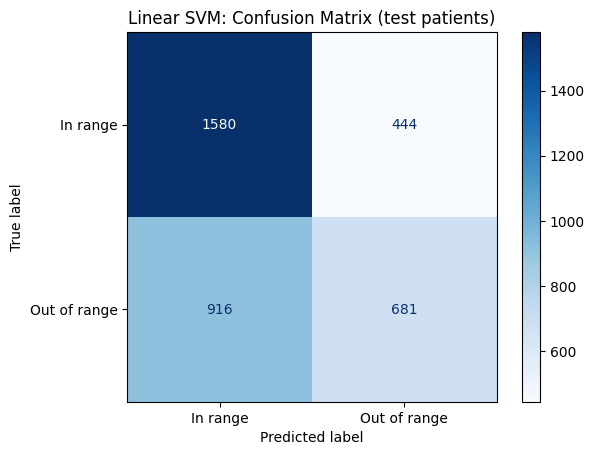

In [10]:
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_train_s, y_train)
y_pred = svm_linear.predict(X_test_s)

print('Test accuracy: {:.1%}'.format(accuracy_score(y_test, y_pred)))
print(classification_report(y_test, y_pred, target_names=['In range', 'Out of range']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['In range', 'Out of range']).plot(cmap='Blues')
plt.title('Linear SVM: Confusion Matrix (test patients)')
plt.show()

In [11]:
results = []
for kernel in ['linear', 'poly', 'rbf']:       # rbf = Radial Basis Function
    model = SVC(kernel=kernel, C=1.0, gamma='scale').fit(X_train_s, y_train)
    results.append({'Kernel': kernel,
                    'Train accuracy': model.score(X_train_s, y_train),
                    'Test accuracy': model.score(X_test_s, y_test)})

print(pd.DataFrame(results).to_string(index=False, float_format=lambda v: '{:.1%}'.format(v)))
print('Baseline: {:.1%}'.format(baseline))

Kernel  Train accuracy  Test accuracy
linear           58.9%          62.4%
  poly           61.0%          62.2%
   rbf           61.5%          61.4%
Baseline: 55.9%


2D SVM test accuracy: 53.9%


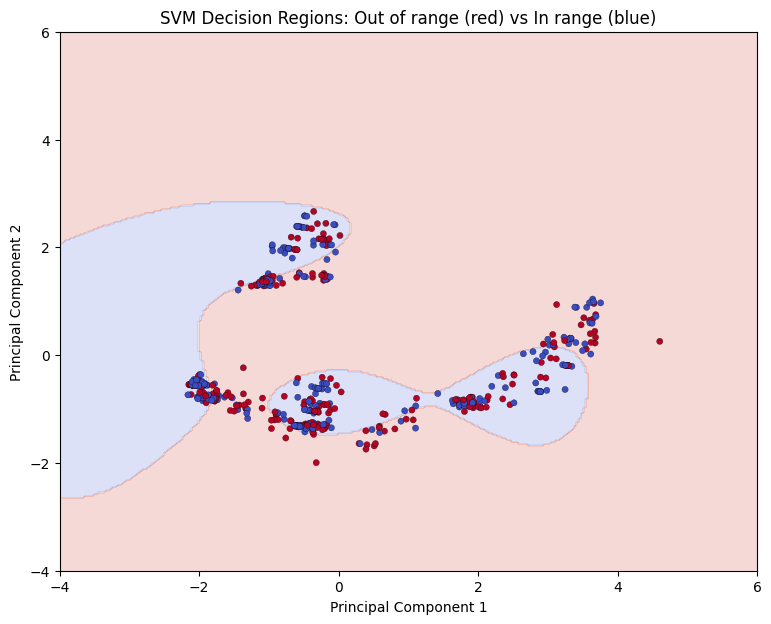

In [12]:
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d  = pca.transform(X_test_s)

svm_2d = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X_train_2d, y_train)
print('2D SVM test accuracy: {:.1%}'.format(svm_2d.score(X_test_2d, y_test)))

xx, yy = np.meshgrid(np.linspace(-4, 6, 300), np.linspace(-4, 6, 300))
zz = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, zz, alpha=0.2, cmap='coolwarm')
sample = np.random.RandomState(0).choice(len(X_test_2d), 600, replace=False)   # plot a sample to keep it readable
plt.scatter(X_test_2d[sample, 0], X_test_2d[sample, 1], c=y_test.values[sample], cmap='coolwarm', s=20, edgecolor='k', linewidth=0.2)
plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
plt.title('SVM Decision Regions: Out of range (red) vs In range (blue)')
plt.show()